In [1]:
!ls track3


Autonomous_car.ipynb road_data
Untitled.ipynb       steering_angles.csv


In [4]:
!pip3 install imgaug
from PIL import Image, ImageFile
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import keras
from keras.models import Sequential, load_model
from keras.optimizers import Adam
from keras.layers import Convolution2D, MaxPooling2D, Dropout, Flatten, Dense
from sklearn.utils import shuffle
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from imgaug import augmenters as iaa
import cv2
import pandas as pd
import ntpath
import random

In [5]:
datadir = 'track3'

In [8]:
# print(data.iloc[1])
def load_img_steering(datadir):
  image_path = []
  steering = []
  # os
  for file in os.listdir(datadir + "/road_data"):
    if file.endswith(".jpg"):
            image_path.append(os.path.join(datadir + "/road_data", file))
            file = str(file)
            steering_angle = file.split("_")[-1].split(".")[0]
            steering_angle = int(steering_angle) - 90
            steering.append(steering_angle)

  image_path = np.asarray(image_path)
  steering = np.asarray(steering)
  return image_path, steering

image_paths, steerings = load_img_steering(datadir)

ValueError: invalid literal for int() with base 10: '120 copy'

In [6]:
image_paths.shape

(1468,)

In [7]:
# Allow loading of truncated images
ImageFile.LOAD_TRUNCATED_IMAGES = True

def check_corrupt_images(image_paths, steering_angles):
    valid_image_paths = []
    valid_steering_angles = []

    for img_path, angle in zip(image_paths, steering_angles):
        try:
            with Image.open(img_path) as img:
                img = img.convert("RGB")  # Convert to RGB mode
                img.load()


            # If no exception, add to valid lists
            valid_image_paths.append(img_path)
            valid_steering_angles.append(angle)

        except (IOError, OSError) as e:
            print(f"Corrupted image found: {img_path} ({str(e)})")
            try:
                os.remove(img_path)  # Delete the corrupted image
                print(f"Deleted: {img_path}")
            except Exception as remove_error:
                print(f"Could not delete {img_path}: {remove_error}")

    # Convert to NumPy arrays
    valid_image_paths = np.array(valid_image_paths)
    valid_steering_angles = np.array(valid_steering_angles)

    print(f"Valid images count: {len(valid_image_paths)}")
    print(f"Valid steering angles count: {len(valid_steering_angles)}")

    return valid_image_paths, valid_steering_angles

# Example usage
image_paths, steerings = check_corrupt_images(image_paths, steerings)


Valid images count: 1468
Valid steering angles count: 1468


In [8]:
image_paths.shape, steerings.shape

((1468,), (1468,))

In [9]:
steering_angles = []
for angle in steerings:
  if (angle > 40):
    angle = 40
  if (angle < -40):
    angle = -40
  steering_angles.append(angle)

steerings = np.array(steering_angles)
filtered_values = steerings[steerings > 40]
# Print the result
print(filtered_values)

filtered_values2 = steerings[steerings < -40]

print(filtered_values2)


[]
[]


In [10]:
num_unique = np.unique(steerings)
print(num_unique)

[-30 -20 -10   0  10  20  30  40]


In [19]:
# import numpy as np

# Ensure steering_angles is a 1D NumPy array
steering_angles = np.array(steerings).flatten()

# Get indices of zero and non-zero steering angles
zero_indices = np.where(steering_angles == 0)[0]
non_zero_indices = np.where(steering_angles != 0)[0]

# Keep only 400 zero-angle samples
selected_zero_indices = np.random.choice(zero_indices, min(400, len(zero_indices)), replace=False)

# Combine selected zero and all non-zero indices
final_indices = np.concatenate((selected_zero_indices, non_zero_indices))

# Shuffle indices
np.random.shuffle(final_indices)

# Filter the dataset
balanced_image_paths = np.array(image_paths)[final_indices]
balanced_steering_angles = np.array(steering_angles)[final_indices]


image_paths = balanced_image_paths
steerings = balanced_steering_angles
print("Original dataset size:", len(image_paths))
print("Balanced dataset size:", len(balanced_image_paths))


Original dataset size: 1204
Balanced dataset size: 1204


[-30.  -27.2 -24.4 -21.6 -18.8 -16.  -13.2 -10.4  -7.6  -4.8  -2.    0.8
   3.6   6.4   9.2  12.   14.8  17.6  20.4  23.2  26.   28.8  31.6  34.4
  37.2  40. ]


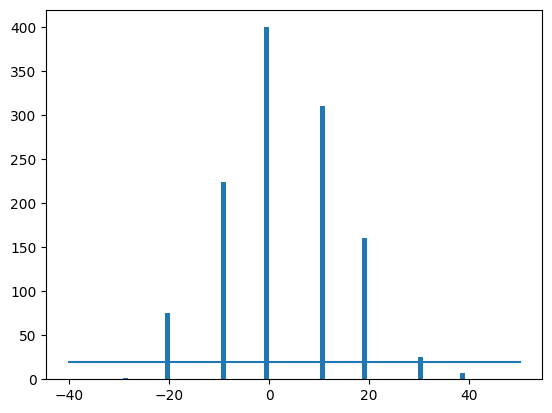

In [20]:
num_bins = 25
samples_per_bin = 20
hist, bins = np.histogram(steerings, num_bins)
# dat = [x - 90.0 for x in bins]
dat = bins
print(dat)
center = (dat[:-1] + dat[1:]) * 0.5
# print(dat)
plt.bar(center, hist, width=1)
plt.plot((np.min(data['steering']), np.max(data['steering'])), (samples_per_bin, samples_per_bin))

In [21]:
X_train, X_valid, y_train, y_valid = train_test_split(image_paths, steerings, test_size=0.2, random_state=6)
print('Training Samples: {}\nValid Samples: {}'.format(len(X_train), len(X_valid)))

Training Samples: 963
Valid Samples: 241


Text(0.5, 1.0, 'Validation set')

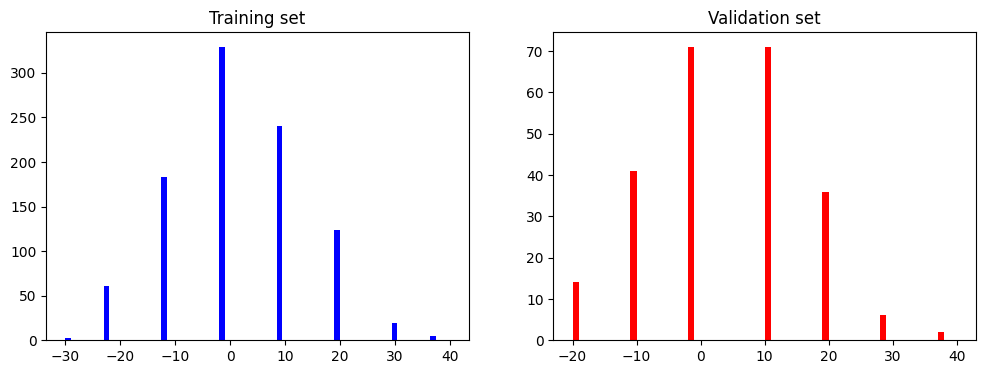

In [22]:
num_bins=20
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=num_bins, width=1, color='blue')
axes[0].set_title('Training set')
axes[1].hist(y_valid, bins=num_bins, width=1, color='red')
axes[1].set_title('Validation set')

In [23]:
def zoom(image):
  zoom = iaa.Affine(scale=(1, 1.3))
  image = zoom.augment_image(image)
  return image

In [24]:
def pan(image):
  pan = iaa.Affine(translate_percent= {"x" : (-0.06, 0.06), "y": (-0.06, 0.06)})
  image = pan.augment_image(image)
  return image

Text(0.5, 1.0, 'Brightness altered image ')

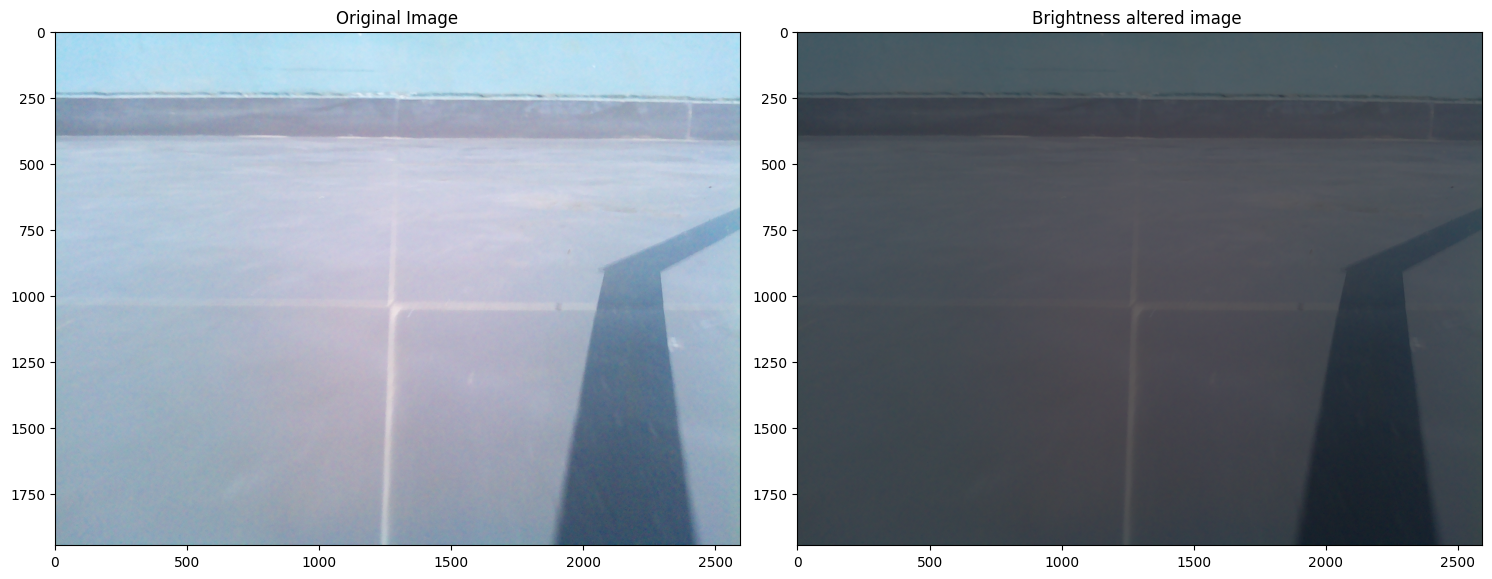

In [25]:
def img_random_brightness(image):
    brightness = iaa.Multiply((0.2, 1.2))
    image = brightness.augment_image(image)
    return image
image = image_paths[random.randint(0, 119)]
original_image = mpimg.imread(image)
brightness_altered_image = img_random_brightness(original_image)

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()

axs[0].imshow(original_image)
axs[0].set_title('Original Image')

axs[1].imshow(brightness_altered_image)
axs[1].set_title('Brightness altered image ')

In [26]:
def img_random_flip(image, steering_angle):
    image = cv2.flip(image,1)

    steering_angle =  -steering_angle
    return image, steering_angle


Text(0.5, 1.0, 'Flipped Image - Steering Angle:0')

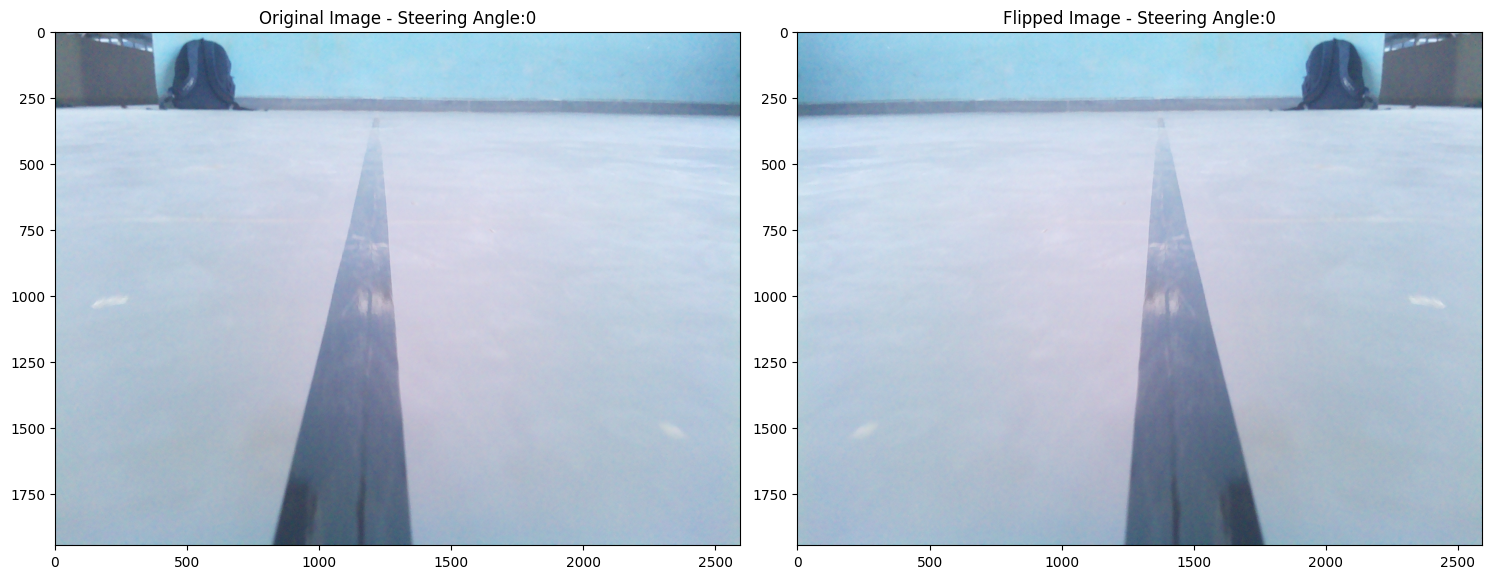

In [27]:
random_index = random.randint(0, 119)
image = image_paths[random_index]
steering_angle = steerings[random_index]


original_image = mpimg.imread(image)
flipped_image, flipped_steering_angle = img_random_flip(original_image, steering_angle)

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()

axs[0].imshow(original_image)
axs[0].set_title('Original Image - ' + 'Steering Angle:' + str(steering_angle))

axs[1].imshow(flipped_image)
axs[1].set_title('Flipped Image - ' + 'Steering Angle:' + str(flipped_steering_angle))

In [28]:
def random_augment(image, steering_angle):
    image = mpimg.imread(image)
    if np.random.rand() < 0.5:
      image = pan(image)
    if np.random.rand() < 0.5:
      image = zoom(image)
    if np.random.rand() < 0.5:
      image = img_random_brightness(image)
    if np.random.rand() < 0.5:
      image, steering = img_random_flip(image, steering_angle)

    return image, steering_angle

734


Text(0.5, 1.0, 'Preprocessed Image')

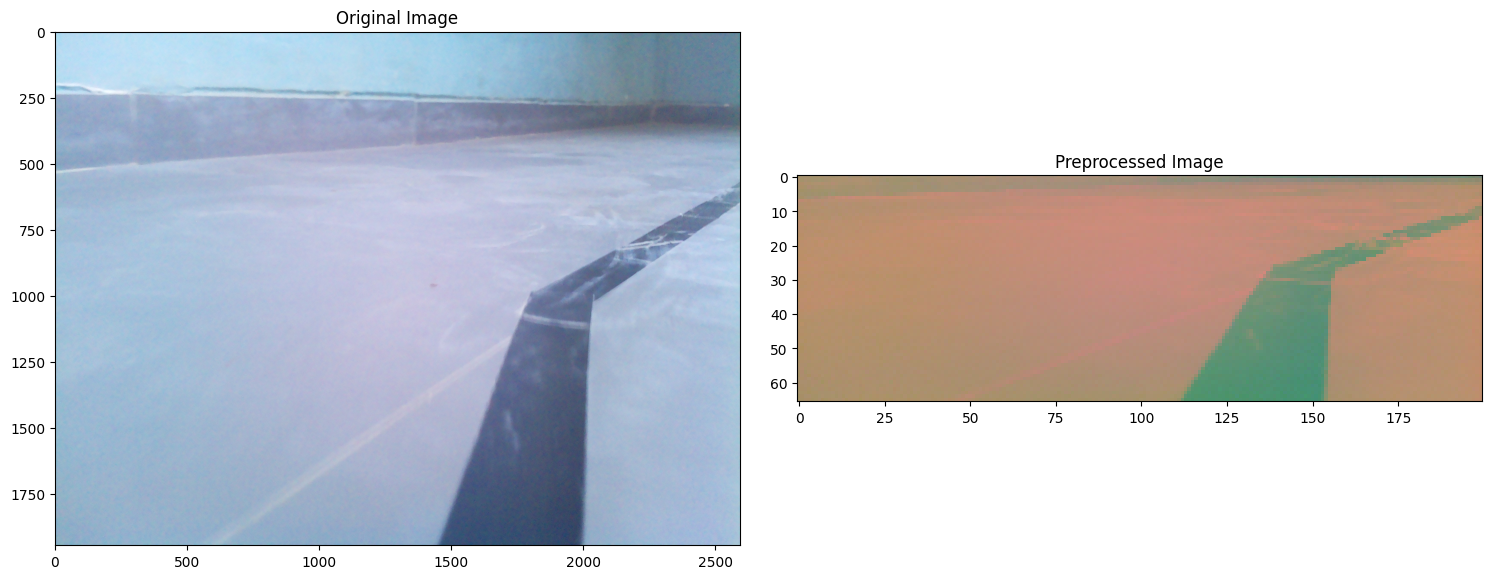

In [29]:
def img_preprocess(img):
    img = img[360:,:,:]
    img = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)
    img = cv2.GaussianBlur(img,  (3, 3), 0)
    img = cv2.resize(img, (200, 66))
    img = img/255
    return img
num = random.randint(0, 1470)
print(num)
image = image_paths[num]
original_image = mpimg.imread(image)
preprocessed_image = img_preprocess(original_image)

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()
axs[0].imshow(original_image)
axs[0].set_title('Original Image')
axs[1].imshow(preprocessed_image)
axs[1].set_title('Preprocessed Image')

In [30]:
steerings

array([ 20,   0, -10, ...,   0,  10,  10])

In [31]:
# import numpy as np
# # from tensorflow.keras.utils import to_categorical

def categorical(array):
    # Define the fixed mapping of unique values to indices
    unique_values = np.array([-30, -20, -10, 0, 10, 20, 30, 40])  # 8 values

    # Ensure all values in 'array' exist in 'unique_values'
    if not np.isin(array, unique_values).all():
        raise ValueError("Input array contains values not in predefined unique_values.")

    # Map values to indices (0 to 7)
    y_indices = np.array([np.where(unique_values == val)[0][0] for val in array])

    # One-hot encode batch labels with fixed num_classes = 8
    y_one_hot = to_categorical(y_indices, num_classes=8)

    return y_one_hot



In [32]:
array = np.array([-30, -20, -10, 0, 10, 20, 30, 40])
new_array = array // 10
new_array = new_array + 3
print(new_array[1])

1


In [26]:
# def categorical(array):
#     # Convert values to indices (ensuring integer indices)
#     indices = (array // 10) + 3  # Mapping -30 → 0, ..., 40 → 7

#     # Initialize a one-hot encoded array
#     one_hot = np.zeros((array.shape[0], 8), dtype=float)  # Ensure dtype=float for 1.0

#     # Assign 1.0 at the correct index positions
#     for i in range(len(array)):
#         one_hot[i, indices[i]] = 1.0  # Correct indexing

#     return one_hot

# # Example usage
# y_train = np.array([-30, -20, -10, 0, 10, 20, 30, 40])
# one_hot_encoded = categorical(y_train)

# print(one_hot_encoded)

In [33]:
def batch_generator(image_paths, steering_ang, batch_size, istraining):

  while True:
    batch_img = []
    batch_steering = []

    for i in range(batch_size):
      random_index = random.randint(0, len(image_paths) - 1)

      if istraining:
        im, steering = random_augment(image_paths[random_index], steering_ang[random_index])
      else:
        im = mpimg.imread(image_paths[random_index])
        steering = steering_ang[random_index]

      im = img_preprocess(im)
      batch_img.append(im)
      batch_steering.append(steering)

    batch_img = np.asarray(batch_img, dtype=np.float32)  # Ensure proper data type
    batch_steering = np.asarray(batch_steering, dtype=np.float32)
    # print(batch_steering)
    batch_steering = categorical(batch_steering)
    # print(batch_img)
    # print(batch_steering)




    yield (batch_img, batch_steering) # outputing a tuple of batch_img and batch_steering

x_train_gen, y_train_gen = next(batch_generator(X_train, y_train, 10, 1))
x_valid_gen, y_valid_gen = next(batch_generator(X_valid, y_valid, 10, 0))

In [31]:
y_train_gen

array([[0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0.]])

Text(0.5, 1.0, 'Validation Image')

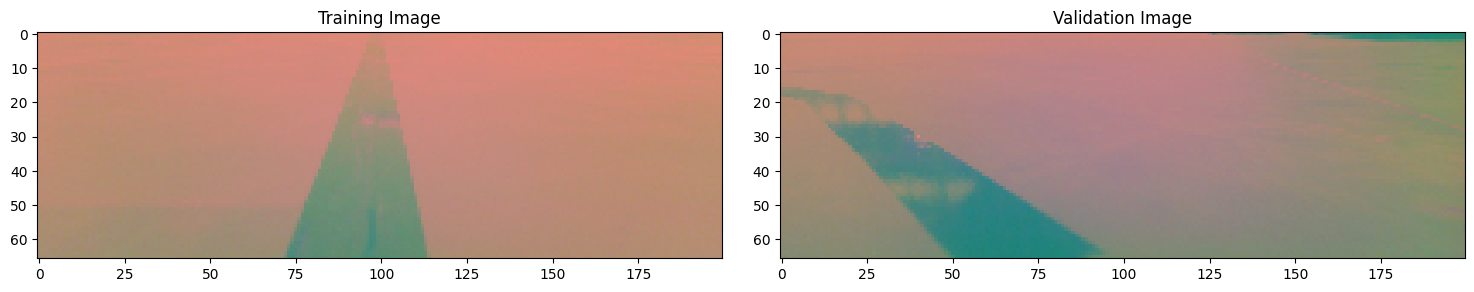

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()

axs[0].imshow(x_train_gen[8])
axs[0].set_title('Training Image')

axs[1].imshow(x_valid_gen[8])
axs[1].set_title('Validation Image')

In [41]:
def nvidia_model():
  model = Sequential()
  model.add(Convolution2D(24, (5, 5), strides =(2, 2),activation='elu', input_shape=(66, 200, 3)))
  model.add(Convolution2D(36, (5, 5), strides =(2, 2), activation='elu'))
  model.add(Convolution2D(48, (5, 5), strides =(2, 2), activation='elu'))
  model.add(Convolution2D(64, (3, 3), activation='elu'))

  model.add(Convolution2D(64, 3, 3, activation='elu'))
  model.add(Dropout(0.5))


  model.add(Flatten())

  model.add(Dense(100, activation = 'elu'))
  model.add(Dropout(0.5))

  model.add(Dense(50, activation = 'elu'))
#   model.add(Dropout(0.5))

  model.add(Dense(25, activation = 'elu'))
#   model.add(Dropout(0.5))

  model.add(Dense(8, activation = 'softmax'))

  optimizer = Adam(learning_rate=1e-4)
  model.compile(loss='mse', optimizer=optimizer)
  return model

In [42]:
model = nvidia_model()
print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 31, 98, 24)     │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 47, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 5, 22, 48)      │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 3, 20, 64)      │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 1, 6, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        38,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           208 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 176,381 (688.99 KB)

 Trainable params: 176,381 (688.99 KB)

 Non-trainable params: 0 (0.00 B)

None


In [43]:
np.unique(y_valid)

array([-20, -10,   0,  10,  20,  30,  40])

In [44]:
history = model.fit(
    batch_generator(X_train, y_train, 80, 1),  # Generator function
    steps_per_epoch=300,
    epochs=10,
    validation_data = batch_generator(X_valid, y_valid, 60, 0),
    validation_steps = 100,
    verbose=1,
    shuffle=True  # `shuffle` should be `True`, not `1`
)

Epoch 1/10


2025-02-27 19:18:31.303615: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


300/300 ━━━━━━━━━━━━━━━━━━━━ 832s 3s/step - loss: 0.1003 - val_loss: 0.0902
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 802s 3s/step - loss: 0.0901 - val_loss: 0.0875
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 800s 3s/step - loss: 0.0872 - val_loss: 0.0874
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 808s 3s/step - loss: 0.0864 - val_loss: 0.0868
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 793s 3s/step - loss: 0.0857 - val_loss: 0.0870
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 754s 3s/step - loss: 0.0853 - val_loss: 0.0880
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 728s 2s/step - loss: 0.0846 - val_loss: 0.0886
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 728s 2s/step - loss: 0.0841 - val_loss: 0.0877
Epoch 9/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 736s 2s/step - loss: 0.0842 - val_loss: 0.0880
Epoch 10/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 733s 2s/step - loss: 0.0835 - val_loss: 0.0879


Text(0.5, 0, 'Epoch')

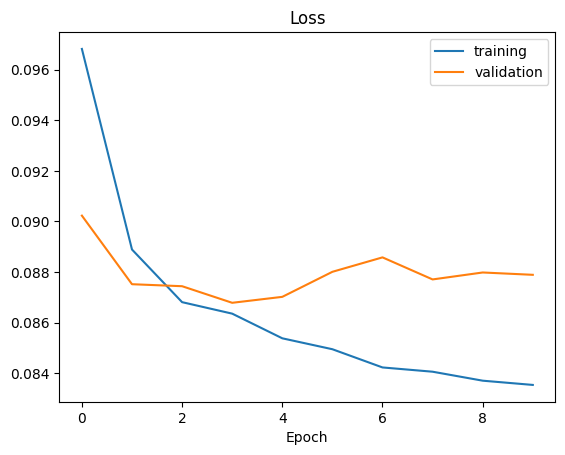

In [45]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['training', 'validation'])
plt.title('Loss')
plt.xlabel('Epoch')

In [46]:
model.save('my_model2.keras')



In [47]:
def img_preprocess(img):
    img = img[360:,:,:]
    img = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)
    img = cv2.GaussianBlur(img,  (3, 3), 0)
    img = cv2.resize(img, (200, 66))
    img = img/255
    print(img.shape)
    return img

136
(66, 200, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Model Prediction: [[0.00588192 0.02890296 0.09395993 0.5505386  0.23778415 0.05869799
  0.01552105 0.00871339]]


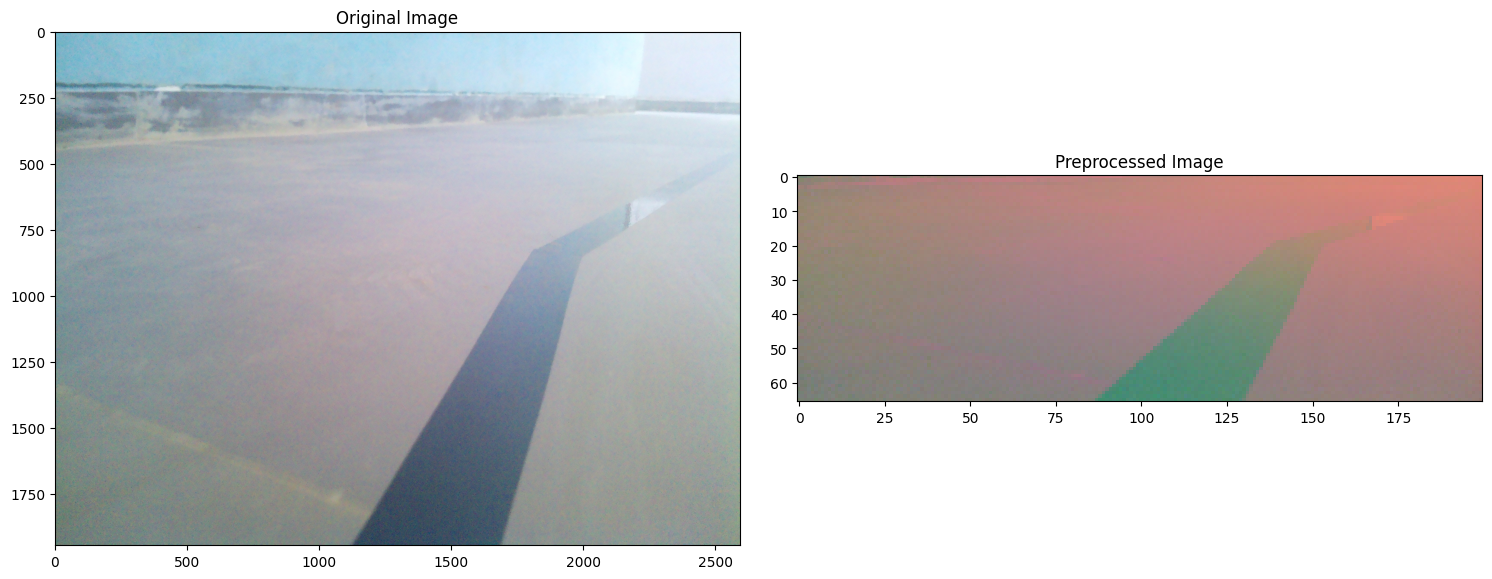

In [95]:
num = random.randint(0, 900)
# num = 44
print(num)
image = image_paths[num]
original_image = mpimg.imread(image)
preprocessed_image = img_preprocess(original_image)
# print(preprocessed_image.shape)

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()
axs[0].imshow(original_image)
axs[0].set_title('Original Image')
axs[1].imshow(preprocessed_image)
axs[1].set_title('Preprocessed Image')
model = load_model("my_model.keras")  # Replace with your model's path

# Prepare input data (example: a single image for a self-driving car model)
input_data = preprocessed_image     #np.random.rand(1, 66, 200, 3)  # Shape (batch_size, height, width, channels)
input_data = np.expand_dims(preprocessed_image, axis=0)  # Shape becomes (1, 66, 200, 3)

# Make prediction
prediction = model.predict(input_data)

# Output the predicted values
print("Model Prediction:", prediction)

In [96]:
angle_mapping = [-30, -20, -10, 0, 10, 20, 30, 40]
predicted_index = np.argmax(prediction)
predicted_angle = angle_mapping[predicted_index]
print(predicted_angle)

0
